# Image Analysis – Masks, Morphology & Evaluation

## Project Overview

This notebook focuses on analyzing the Field-PDD dataset, inspecting ground-truth masks, checking dataset consistency, analyzing connected components, and experimenting with morphological operations.

## Objectives

- Inspect the dataset structure and distribution.
- Verify image and mask integrity.
- Analyze ground-truth mask pixel values.
- Examine the consistency between black images and label masks.
- Analyze connected components.
- Apply morphological operations and compare their effects.
- Prepare evaluation metrics for segmentation analysis.

## 1. Import Libraries

This section imports the Python libraries required for dataset handling, image processing, numerical operations, and visualization.

In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2

from PIL import Image
from collections import Counter, defaultdict

## Dataset Loading

This section loads the dataset manifest, which contains the image paths, black image paths, label mask paths, disease classes, and dataset splits.

In [83]:
df = pd.read_csv('/content/image-project-/split.csv')

print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
display(df.head(10))

Shape: (240, 6)

Columns:
['class', 'name', 'image', 'black', 'label', 'split']

First 10 rows:


,class,name,image,black,label,split
0,soybean_bacterial_blight,Soybean_0090,soybean_bacterial_blight/Soybean_0090.jpg,soybean_bacterial_blight/Soybean_0090_black.png,soybean_bacterial_blight/Soybean_0090_label.png,train
1,wheat_stripe_rust,Wheat_C230514_0082,wheat_stripe_rust/Wheat_C230514_0082.jpg,wheat_stripe_rust/Wheat_C230514_0082_black.png,wheat_stripe_rust/Wheat_C230514_0082_label.png,train
2,soybean_bacterial_blight,Soybean_0166,soybean_bacterial_blight/Soybean_0166.jpg,soybean_bacterial_blight/Soybean_0166_black.png,soybean_bacterial_blight/Soybean_0166_label.png,train
3,cedar_apple_rust,Apple_0369,cedar_apple_rust/Apple_0369.jpg,cedar_apple_rust/Apple_0369_black.png,cedar_apple_rust/Apple_0369_label.png,train
4,cedar_apple_rust,Apple_0241,cedar_apple_rust/Apple_0241.jpg,cedar_apple_rust/Apple_0241_black.png,cedar_apple_rust/Apple_0241_label.png,train
5,wheat_stripe_rust,Wheat_C230514_0089,wheat_stripe_rust/Wheat_C230514_0089.jpg,wheat_stripe_rust/Wheat_C230514_0089_black.png,wheat_stripe_rust/Wheat_C230514_0089_label.png,train
6,wheat_stripe_rust,Wheat_C230514_0092,wheat_stripe_rust/Wheat_C230514_0092.jpg,wheat_stripe_rust/Wheat_C230514_0092_black.png,wheat_stripe_rust/Wheat_C230514_0092_label.png,train
7,soybean_bacterial_blight,Soybean_0061,soybean_bacterial_blight/Soybean_0061.jpg,soybean_bacterial_blight/Soybean_0061_black.png,soybean_bacterial_blight/Soybean_0061_label.png,train
8,wheat_stripe_rust,Wheat_C230514_0084,wheat_stripe_rust/Wheat_C230514_0084.jpg,wheat_stripe_rust/Wheat_C230514_0084_black.png,wheat_stripe_rust/Wheat_C230514_0084_label.png,train
9,soybean_bacterial_blight,Soybean_0179,soybean_bacterial_blight/Soybean_0179.jpg,soybean_bacterial_blight/Soybean_0179_black.png,soybean_bacterial_blight/Soybean_0179_label.png,train


## Dataset Overview

This section examines the dataset distribution across disease classes and data splits. It also checks for duplicated sample names.

In [84]:
print("Images in each split:")
print(df['split'].value_counts())

print("\nImages in each class:")
print(df['class'].value_counts())

print("\nClass distribution in each split:")
display(pd.crosstab(df['class'], df['split']))

print("\nDuplicate sample names:")
print(df['name'].duplicated().sum())

Images in each split:
split
train    168
val       36
test      36
Name: count, dtype: int64

Images in each class:
class
soybean_bacterial_blight    80
wheat_stripe_rust           80
cedar_apple_rust            80
Name: count, dtype: int64

Class distribution in each split:


split,test,train,val
class,,,
cedar_apple_rust,12,56,12
soybean_bacterial_blight,12,56,12
wheat_stripe_rust,12,56,12



Duplicate sample names:
0


### Dataset Overview – Results

The dataset contains 240 samples distributed across three classes.

- Training set: 168 images (70%).
- Validation set: 36 images (15%).
- Test set: 36 images (15%).

Each class contains 80 images, with 56 training samples, 12 validation samples, and 12 testing samples.

No duplicate sample names were found.

**Conclusion:** The dataset has a balanced class distribution and an equal split ratio across all three classes.

## Dataset Download

This section downloads the Field-PDD dataset using KaggleHub and retrieves the dataset directory.

In [85]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("alexzcheny/testdataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'testdataset' dataset.
Path to dataset files: /kaggle/input/testdataset


## Dataset Directory Structure

This section identifies the dataset location and displays its folder structure.

In [86]:
DATASET_PATH = path
DATASET_DIR = os.path.join(DATASET_PATH, "Dataset")

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:5]:
            print("  " * (level + 1) + file)

testdataset/
  Dataset/
    soybean_bacterial_blight/
      Soybean_0243_label.png
      Soybean_0060_label.png
      Soybean_0027_black.png
      Soybean_0250.jpg
      Soybean_0061_black.png
    wheat_stripe_rust/
      Wheat_C230514_0023.jpg
      Wheat_C230514_0062.jpg
      Wheat_C230514_0012.jpg
      Wheat_C230514_0098_label.png
      Wheat_C230514_0032_label.png
    cedar_apple_rust/
      Apple_0064_label.png
      Apple_0208.jpg
      Apple_0322_label.png
      Apple_0218_black.png
      Apple_0323.jpg
  OriginalData/
    soybean_bacterial_blight/
      Soybean_0250.jpg
      Soybean_0027.jpg
      Soybean_0031.jpg
      Soybean_0071.jpg
      Soybean_0026.jpg
    wheat_stripe_rust/
      Wheat_C230514_0023.jpg
      Wheat_C230514_0062.jpg
      Wheat_C230514_0012.jpg
      Wheat_C230514_0013.jpg
      Wheat_C230514_0073.jpg
    cedar_apple_rust/
      Apple_0208.jpg
      Apple_0323.jpg
      Apple_0333.jpg
      Apple_0334.jpg
      Apple_0277.jpg


## Dataset Integrity – File Existence

This section verifies that all original images, black images, and label masks listed in the manifest exist in the dataset directory.

In [87]:
DATASET_DIR = os.path.join(DATASET_PATH, "Dataset")

missing = []

for _, row in df.iterrows():
    for column in ["image", "black", "label"]:
        file_path = os.path.join(DATASET_DIR, row[column])

        if not os.path.isfile(file_path):
            missing.append((row["name"], column, file_path))

print("Total samples:", len(df))
print("Expected files:", len(df) * 3)
print("Missing files:", len(missing))

if missing:
    print("\nMissing files details:")
    for item in missing[:20]:
        print(item)
else:
    print("\nAll image and mask files exist!")

Total samples: 240
Expected files: 720
Missing files: 0

All image and mask files exist!


## Image and Mask Dimensions

This section checks whether the original image, black image, and label mask have matching dimensions for every sample.

In [88]:
dimension_errors = []

for _, row in df.iterrows():
    image_path = os.path.join(DATASET_DIR, row["image"])
    black_path = os.path.join(DATASET_DIR, row["black"])
    label_path = os.path.join(DATASET_DIR, row["label"])

    with Image.open(image_path) as img:
        image_size = img.size

    with Image.open(black_path) as img:
        black_size = img.size

    with Image.open(label_path) as img:
        label_size = img.size

    if image_size != black_size or image_size != label_size:
        dimension_errors.append({
            "name": row["name"],
            "image": image_size,
            "black": black_size,
            "label": label_size
        })

print("Total checked:", len(df))
print("Dimension mismatches:", len(dimension_errors))

if dimension_errors:
    for error in dimension_errors[:10]:
        print(error)
else:
    print("All image, black, and label dimensions match!")

Total checked: 240
Dimension mismatches: 0
All image, black, and label dimensions match!


### Image and Mask Dimensions Validation

All 240 samples were checked to verify that each original image, black mask, and label mask has matching dimensions.

- Total samples checked: 240
- Dimension mismatches: 0
- Result: All image and mask dimensions match.

**Conclusion:** The dataset passed the image and mask dimension consistency check.

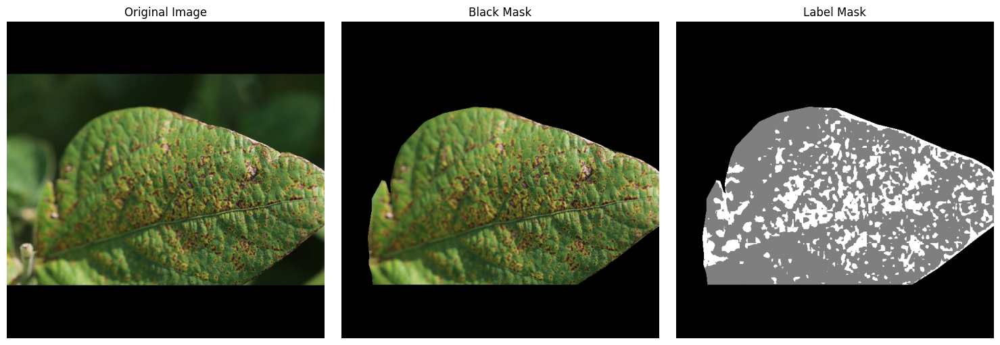

Sample: Soybean_0090
Image mode: RGB
Black mode: RGB
Label mode: L
Black unique values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
Label unique values: [  0 127 255]


In [89]:
sample = df.iloc[0]

image_path = os.path.join(DATASET_DIR, sample["image"])
black_path = os.path.join(DATASET_DIR, sample["black"])
label_path = os.path.join(DATASET_DIR, sample["label"])

image = Image.open(image_path)
black = Image.open(black_path)
label = Image.open(label_path)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")

axes[1].imshow(black, cmap="gray")
axes[1].set_title("Black Mask")

axes[2].imshow(label, cmap="gray")
axes[2].set_title("Label Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Sample:", sample["name"])
print("Image mode:", image.mode)
print("Black mode:", black.mode)
print("Label mode:", label.mode)

print("Black unique values:", np.unique(np.array(black))[:20])
print("Label unique values:", np.unique(np.array(label))[:20])

### Label Mask Visualization

This section visualizes the different pixel values in the label mask using different colors.

- 0: Black
- 127: Yellow
- 255: Red

The visualization helps distinguish the different regions in the label mask.

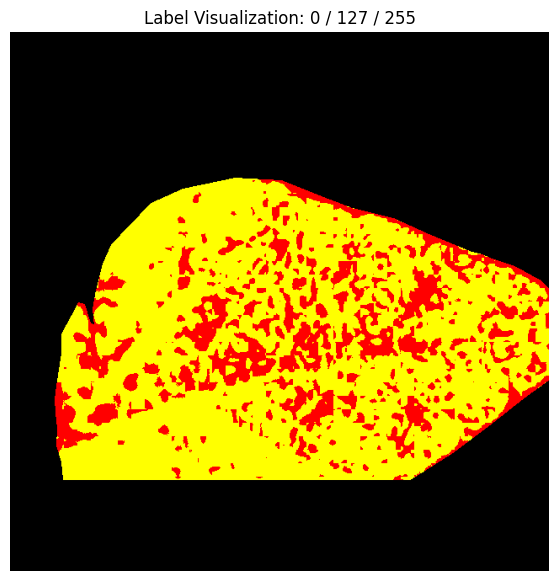

In [90]:
label_array = np.array(label)

colored_label = np.zeros(
    (label_array.shape[0], label_array.shape[1], 3),
    dtype=np.uint8
)

colored_label[label_array == 0] = [0, 0, 0]
colored_label[label_array == 127] = [255, 255, 0]
colored_label[label_array == 255] = [255, 0, 0]

plt.figure(figsize=(7, 7))
plt.imshow(colored_label)
plt.title("Label Visualization: 0 / 127 / 255")
plt.axis("off")
plt.show()

### Label Mask Integrity Check

This section checks all label masks to identify their unique pixel values and verify that each mask is a grayscale image.

The check also records any files that cannot be read correctly.

In [91]:
label_values = Counter()
label_errors = []

for _, row in df.iterrows():
    path = os.path.join(DATASET_DIR, row["label"])

    try:
        mask = np.array(Image.open(path))

        if mask.ndim != 2:
            label_errors.append((row["name"], "Not grayscale"))
            continue

        values = np.unique(mask)
        label_values.update(values.tolist())

    except Exception as e:
        label_errors.append((row["name"], str(e)))

print("Pixel values found across all labels:")
print(label_values)

print("\nNumber of labels checked:", len(df))
print("Label errors:", len(label_errors))

if label_errors:
    print(label_errors[:10])

Pixel values found across all labels:
Counter({0: 240, 127: 240, 255: 240})

Number of labels checked: 240
Label errors: 0


### Label Pixel Distribution Analysis

This section calculates the total number of pixels for each unique value across all 240 label masks.

It also calculates the percentage of each pixel value in the complete dataset to understand the distribution of the mask regions.

In [92]:
pixel_counts = defaultdict(int)

for _, row in df.iterrows():
    path = os.path.join(DATASET_DIR, row["label"])
    mask = np.array(Image.open(path))

    values, counts = np.unique(mask, return_counts=True)

    for value, count in zip(values, counts):
        pixel_counts[int(value)] += int(count)

total = sum(pixel_counts.values())

print("Total pixels:", total)

for value in sorted(pixel_counts):
    count = pixel_counts[value]
    percentage = count / total * 100

    print(
        f"Value {value}: {count:,} pixels "
        f"({percentage:.2f}%)"
    )

Total pixels: 98304000
Value 0: 77,110,575 pixels (78.44%)
Value 127: 17,597,089 pixels (17.90%)
Value 255: 3,596,336 pixels (3.66%)


### Dataset-wide Black and Label Consistency Analysis

This section performs the same black pixel consistency check across all 240 samples.

It counts black pixels associated with each label value and records images containing black pixels where the label value is 255.

In [93]:
consistency_counts = {
    0: {"black": 0, "non_black": 0},
    127: {"black": 0, "non_black": 0},
    255: {"black": 0, "non_black": 0}
}

exception_images = []

for _, row in df.iterrows():

    black_path = os.path.join(DATASET_DIR, row["black"])
    label_path = os.path.join(DATASET_DIR, row["label"])

    black_array = np.array(
        Image.open(black_path).convert("RGB")
    )

    label_array = np.array(
        Image.open(label_path)
    )

    black_pixels = np.all(black_array == 0, axis=2)

    exception_count = np.sum(
        (label_array == 255) & black_pixels
    )

    if exception_count > 0:
        exception_images.append({
            "name": row["name"],
            "split": row["split"],
            "exception_pixels": int(exception_count)
        })

    for value in [0, 127, 255]:

        total = np.sum(label_array == value)

        black_count = np.sum(
            (label_array == value) & black_pixels
        )

        non_black_count = total - black_count

        consistency_counts[value]["black"] += int(black_count)
        consistency_counts[value]["non_black"] += int(non_black_count)

print("Dataset-wide consistency results:")

for value in [0, 127, 255]:
    print(f"\nLabel value: {value}")
    print("Black pixels:", consistency_counts[value]["black"])
    print("Non-black pixels:", consistency_counts[value]["non_black"])

print("\nImages with exceptions:", len(exception_images))

Dataset-wide consistency results:

Label value: 0
Black pixels: 77110575
Non-black pixels: 0

Label value: 127
Black pixels: 0
Non-black pixels: 17597089

Label value: 255
Black pixels: 125
Non-black pixels: 3596211

Images with exceptions: 17


### Black and Label Mask Exceptions Report

This section lists samples containing pixels where the black image is black but the corresponding label pixel has value 255.

These cases are recorded for further visual inspection and should not automatically be considered segmentation errors.

In [94]:
exceptions_df = pd.DataFrame(exception_images)

display(
    exceptions_df.sort_values(
        by="exception_pixels",
        ascending=False
    )
)

if not exceptions_df.empty:

    print(
        "Total exception pixels:",
        exceptions_df["exception_pixels"].sum()
    )

    print("\nExceptions by split:")
    print(exceptions_df["split"].value_counts())

else:
    print("No exceptions were detected.")


,name,split,exception_pixels
10,Apple_0301,train,59
13,Apple_0098,train,25
1,Apple_0323,train,11
11,Soybean_0026,train,5
5,Apple_0058,train,5
0,Soybean_0166,train,3
4,Soybean_0054,train,2
3,Soybean_0210,train,2
2,Apple_0092,train,2
12,Apple_0333,train,2


Total exception pixels: 125

Exceptions by split:
split
train    14
val       2
test      1
Name: count, dtype: int64


### All Exception Samples Visualization

This section displays all samples containing detected black and label mismatches.

Red overlays indicate the locations of pixels where the black image is black while the label value is 255.

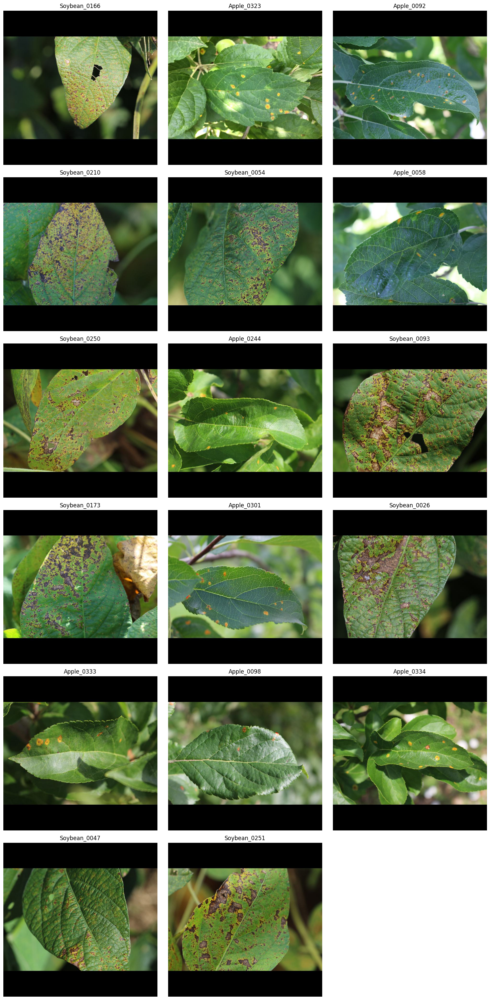

In [95]:

exception_names = exceptions_df["name"].tolist()

n = len(exception_names)
cols = 3
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(
    rows, cols,
    figsize=(15, 5 * rows),
    squeeze=False
)

for ax, name in zip(axes.flat, exception_names):

    row = df[df["name"] == name].iloc[0]

    image_path = os.path.join(DATASET_DIR, row["image"])
    black_path = os.path.join(DATASET_DIR, row["black"])
    label_path = os.path.join(DATASET_DIR, row["label"])

    original = np.array(
        Image.open(image_path).convert("RGB")
    )

    black_array = np.array(
        Image.open(black_path).convert("RGB")
    )

    label_array = np.array(
        Image.open(label_path)
    )

    black_pixels = np.all(black_array == 0, axis=2)
    exception_mask = (label_array == 255) & black_pixels

    overlay = original.copy()
    overlay[exception_mask] = [255, 0, 0]

    ax.imshow(overlay)
    ax.set_title(name)
    ax.axis("off")

for ax in axes.flat[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()


### Dataset-wide Connected Components Analysis

This section applies connected component analysis to all 240 label masks.

For each sample, it records the number of connected components, the largest component area, the smallest component area, and the average component area.

In [96]:
results = []

for _, row in df.iterrows():

    label_path = os.path.join(DATASET_DIR, row["label"])

    mask = np.array(Image.open(label_path))

    binary_mask = (mask == 255).astype(np.uint8)

    num_labels, components, stats, centroids = cv2.connectedComponentsWithStats(
        binary_mask,
        connectivity=8
    )

    areas = stats[1:, cv2.CC_STAT_AREA]

    results.append({
        "name": row["name"],
        "class": row["class"],
        "split": row["split"],
        "num_components": len(areas),
        "largest_area": areas.max() if len(areas) else 0,
        "smallest_area": areas.min() if len(areas) else 0,
        "average_area": areas.mean() if len(areas) else 0
    })

morphology_df = pd.DataFrame(results)

display(morphology_df.head(10))

,name,class,split,num_components,largest_area,smallest_area,average_area
0,Soybean_0090,soybean_bacterial_blight,train,288,3238,1,143.947917
1,Wheat_C230514_0082,wheat_stripe_rust,train,6,1277,17,317.333333
2,Soybean_0166,soybean_bacterial_blight,train,349,2517,1,52.154728
3,Apple_0369,cedar_apple_rust,train,8,303,79,168.375000
4,Apple_0241,cedar_apple_rust,train,7,991,71,328.000000
5,Wheat_C230514_0089,wheat_stripe_rust,train,24,12900,17,698.125000
6,Wheat_C230514_0092,wheat_stripe_rust,train,11,29273,17,2717.727273
7,Soybean_0061,soybean_bacterial_blight,train,259,4658,1,48.447876
8,Wheat_C230514_0084,wheat_stripe_rust,train,8,15054,17,2067.500000
9,Soybean_0179,soybean_bacterial_blight,train,333,3590,1,65.426426


### Connected Components Statistical Summary

This section summarizes the connected component measurements across the complete dataset.

It provides descriptive statistics for the number of components and their areas.

In [97]:
print("Connected Components Summary:")

display(
    morphology_df[
        ["num_components", "largest_area", "smallest_area", "average_area"]
    ].describe()
)

Connected Components Summary:


,num_components,largest_area,smallest_area,average_area
count,240.000000,240.000000,240.000000,240.000000
mean,92.858333,6547.208333,129.525000,478.389662
std,125.973551,9229.414773,462.429494,694.122391
min,1.000000,112.000000,1.000000,47.403448
25%,6.000000,693.250000,1.000000,137.472619
50%,14.000000,2536.000000,17.000000,249.013441
75%,199.250000,8897.250000,76.500000,600.000000
max,480.000000,54533.000000,4589.000000,6641.500000


### Connected Components Analysis by Class

This section groups the connected component measurements by disease class.

The mean number of components and mean largest component area are calculated for each class to compare their mask characteristics.

In [98]:
class_summary = morphology_df.groupby("class")[
    ["num_components", "largest_area", "average_area"]
].mean()

display(class_summary)

,num_components,largest_area,average_area
class,,,
cedar_apple_rust,6.0375,736.8250,538.484647
soybean_bacterial_blight,258.0125,12557.9875,142.163859
wheat_stripe_rust,14.5250,6346.8125,754.520479


### Average Number of Connected Components by Class

This bar chart compares the average number of connected components across the three disease classes.

It helps identify differences in the number of separate regions detected in each class.

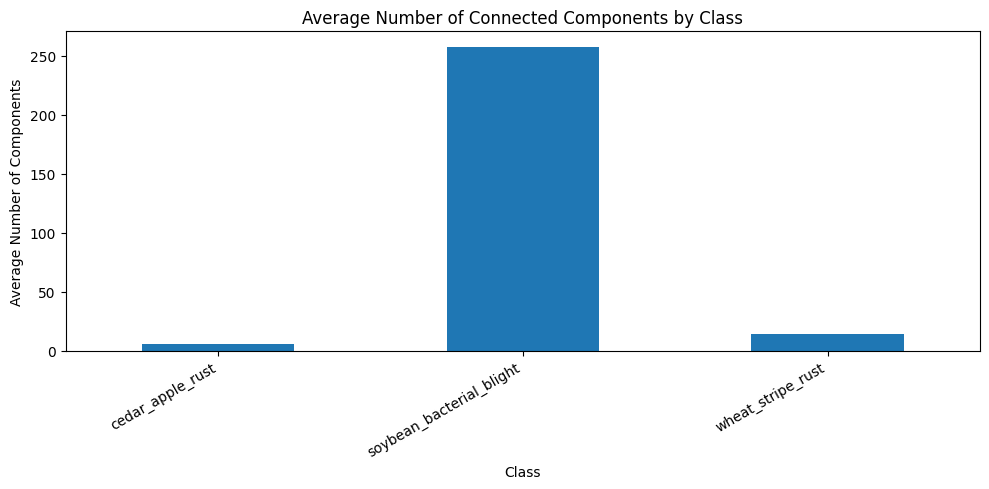

In [99]:
plt.figure(figsize=(10, 5))

class_summary["num_components"].plot(
    kind="bar",
    title="Average Number of Connected Components by Class"
)

plt.xlabel("Class")
plt.ylabel("Average Number of Components")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Average Largest Component Area by Class

This bar chart compares the average area of the largest connected component across the three classes.

It provides a comparison of the largest detected regions in the binary masks.

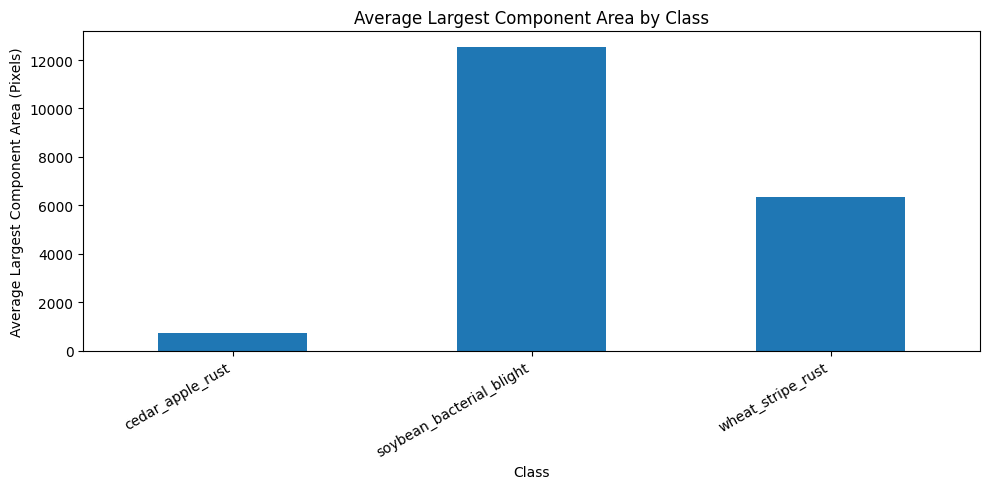

In [100]:
plt.figure(figsize=(10, 5))

class_summary["largest_area"].plot(
    kind="bar",
    title="Average Largest Component Area by Class"
)

plt.xlabel("Class")
plt.ylabel("Average Largest Component Area (Pixels)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Morphological Operations

Morphological operations are applied to binary masks to study changes in their shapes and structures.

This section applies Opening and Closing operations to a selected binary mask using a 3×3 structuring element.

- Opening: Erosion followed by Dilation.
- Closing: Dilation followed by Erosion.

In [101]:
row = df.iloc[0]

label_path = os.path.join(DATASET_DIR, row["label"])
mask = np.array(Image.open(label_path))

binary_mask = (mask == 255).astype(np.uint8)

kernel = np.ones((3, 3), np.uint8)

opening = cv2.morphologyEx(
    binary_mask, cv2.MORPH_OPEN, kernel
)

closing = cv2.morphologyEx(
    binary_mask, cv2.MORPH_CLOSE, kernel
)

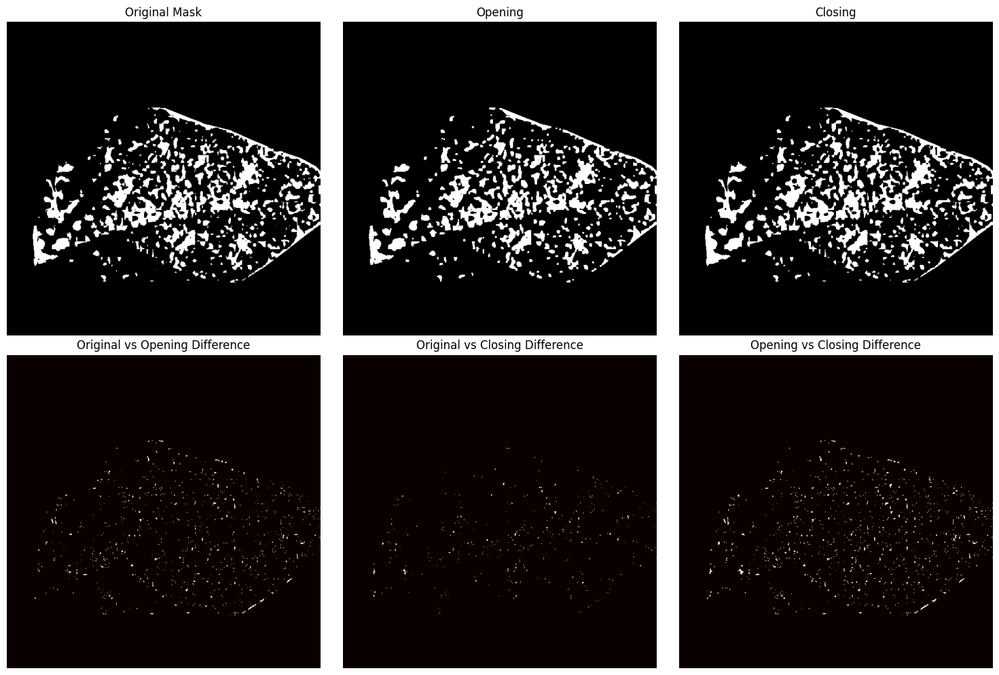

In [102]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes[0, 0].imshow(binary_mask, cmap="gray")
axes[0, 0].set_title("Original Mask")

axes[0, 1].imshow(opening, cmap="gray")
axes[0, 1].set_title("Opening")

axes[0, 2].imshow(closing, cmap="gray")
axes[0, 2].set_title("Closing")

axes[1, 0].imshow(
    cv2.absdiff(binary_mask, opening),
    cmap="hot"
)
axes[1, 0].set_title("Original vs Opening Difference")

axes[1, 1].imshow(
    cv2.absdiff(binary_mask, closing),
    cmap="hot"
)
axes[1, 1].set_title("Original vs Closing Difference")

axes[1, 2].imshow(
    np.logical_xor(opening, closing),
    cmap="hot"
)
axes[1, 2].set_title("Opening vs Closing Difference")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Visual Comparison of Morphological Kernel Sizes

This section visually compares the effects of different structuring element sizes on the binary mask.

Opening and Closing are applied using 3×3, 5×5, and 7×7 kernels to observe how kernel size affects the mask structure.

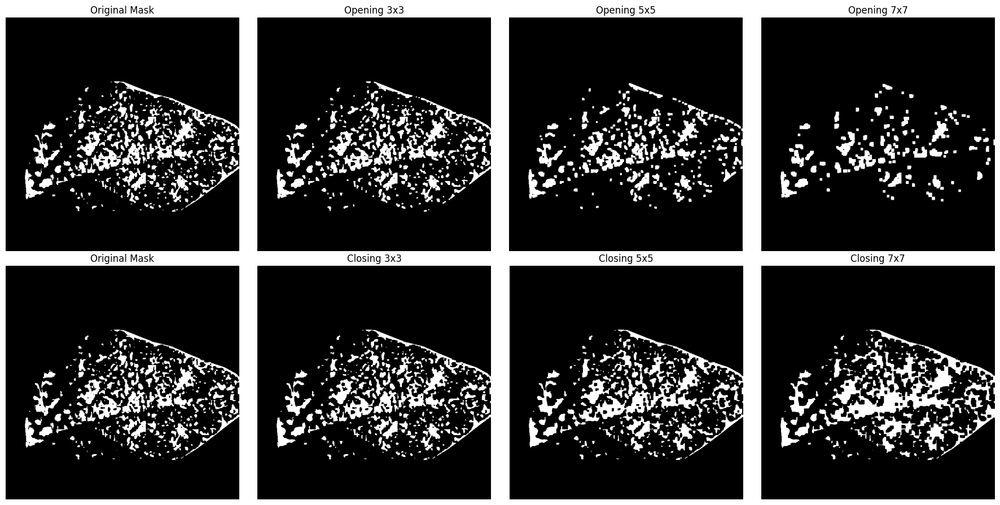

In [103]:
kernel_sizes = [3, 5, 7]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

axes[0, 0].imshow(binary_mask, cmap="gray")
axes[0, 0].set_title("Original Mask")

axes[1, 0].imshow(binary_mask, cmap="gray")
axes[1, 0].set_title("Original Mask")

for i, size in enumerate(kernel_sizes, start=1):

    kernel = np.ones((size, size), np.uint8)

    opened = cv2.morphologyEx(
        binary_mask,
        cv2.MORPH_OPEN,
        kernel
    )

    closed = cv2.morphologyEx(
        binary_mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    axes[0, i].imshow(opened, cmap="gray")
    axes[0, i].set_title(f"Opening {size}x{size}")

    axes[1, i].imshow(closed, cmap="gray")
    axes[1, i].set_title(f"Closing {size}x{size}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [104]:

morphology_results = []

kernel_sizes = [3, 5, 7]

for _, row in df.iterrows():

    label_path = os.path.join(DATASET_DIR, row["label"])
    mask = np.array(Image.open(label_path))

    # Convert the disease region (255) into a binary mask
    binary_mask = (mask == 255).astype(np.uint8)

    for size in kernel_sizes:

        kernel = np.ones((size, size), np.uint8)

        opening = cv2.morphologyEx(
            binary_mask,
            cv2.MORPH_OPEN,
            kernel
        )

        closing = cv2.morphologyEx(
            binary_mask,
            cv2.MORPH_CLOSE,
            kernel
        )

        for operation_name, processed_mask in [
            ("Opening", opening),
            ("Closing", closing)
        ]:

            intersection = np.logical_and(
                binary_mask, processed_mask
            ).sum()

            union = np.logical_or(
                binary_mask, processed_mask
            ).sum()

            iou = intersection / union if union > 0 else 1.0

            morphology_results.append({
                "name": row["name"],
                "class": row["class"],
                "split": row["split"],
                "operation": operation_name,
                "kernel_size": f"{size}x{size}",
                "original_pixels": int(binary_mask.sum()),
                "processed_pixels": int(processed_mask.sum()),
                "changed_pixels": int(
                    np.sum(binary_mask != processed_mask)
                ),
                "IoU": float(iou)
            })

morphology_results_df = pd.DataFrame(morphology_results)

print("Total samples:", len(df))
print("Total experiment records:", len(morphology_results_df))

display(morphology_results_df.head(10))


Total samples: 240
Total experiment records: 1440


,name,class,split,operation,kernel_size,original_pixels,processed_pixels,changed_pixels,IoU
0,Soybean_0090,soybean_bacterial_blight,train,Opening,3x3,41457,39251,2206,0.946788
1,Soybean_0090,soybean_bacterial_blight,train,Closing,3x3,41457,42275,818,0.980651
2,Soybean_0090,soybean_bacterial_blight,train,Opening,5x5,41457,32572,8885,0.785682
3,Soybean_0090,soybean_bacterial_blight,train,Closing,5x5,41457,44858,3401,0.924183
4,Soybean_0090,soybean_bacterial_blight,train,Opening,7x7,41457,21834,19623,0.526666
5,Soybean_0090,soybean_bacterial_blight,train,Closing,7x7,41457,50711,9254,0.817515
6,Wheat_C230514_0082,wheat_stripe_rust,train,Opening,3x3,1904,1894,10,0.994748
7,Wheat_C230514_0082,wheat_stripe_rust,train,Closing,3x3,1904,1912,8,0.995816
8,Wheat_C230514_0082,wheat_stripe_rust,train,Opening,5x5,1904,1760,144,0.924370
9,Wheat_C230514_0082,wheat_stripe_rust,train,Closing,5x5,1904,1926,22,0.988577


In [105]:

morphology_summary = (
    morphology_results_df
    .groupby(["operation", "kernel_size"])
    [["original_pixels", "processed_pixels",
      "changed_pixels", "IoU"]]
    .mean()
    .reset_index()
)

display(morphology_summary.round(4))


,operation,kernel_size,original_pixels,processed_pixels,changed_pixels,IoU
0,Closing,3x3,14984.7333,15291.6167,306.8833,0.9865
1,Closing,5x5,14984.7333,16195.5417,1210.8083,0.9532
2,Closing,7x7,14984.7333,17750.8333,2766.1000,0.9068
3,Opening,3x3,14984.7333,14300.6042,684.1292,0.9712
4,Opening,5x5,14984.7333,12574.1000,2410.6333,0.8846
5,Opening,7x7,14984.7333,10185.5083,4799.2250,0.7246


In [106]:

class_morphology_summary = (
    morphology_results_df
    .groupby(["class", "operation", "kernel_size"])
    [["changed_pixels", "IoU"]]
    .mean()
    .reset_index()
)

display(class_morphology_summary.round(4))


,class,operation,kernel_size,changed_pixels,IoU
0,cedar_apple_rust,Closing,3x3,0.5250,0.9997
1,cedar_apple_rust,Closing,5x5,3.0000,0.9985
2,cedar_apple_rust,Closing,7x7,7.4250,0.9962
3,cedar_apple_rust,Opening,3x3,14.2500,0.9899
4,cedar_apple_rust,Opening,5x5,55.6375,0.9611
5,cedar_apple_rust,Opening,7x7,155.2375,0.8872
6,soybean_bacterial_blight,Closing,3x3,715.0125,0.9798
7,soybean_bacterial_blight,Closing,5x5,3016.1125,0.9188
8,soybean_bacterial_blight,Closing,7x7,7193.2250,0.8241
9,soybean_bacterial_blight,Opening,3x3,1975.7375,0.9321


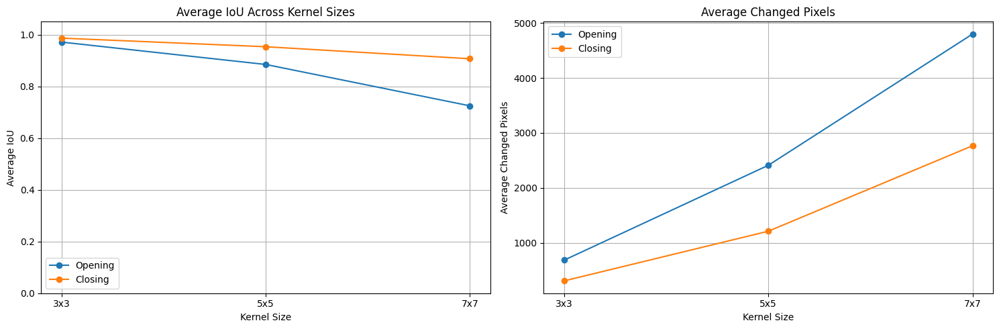

In [107]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for operation in ["Opening", "Closing"]:

    data = morphology_summary[
        morphology_summary["operation"] == operation
    ]

    axes[0].plot(
        data["kernel_size"],
        data["IoU"],
        marker="o",
        label=operation
    )

axes[0].set_title("Average IoU Across Kernel Sizes")
axes[0].set_xlabel("Kernel Size")
axes[0].set_ylabel("Average IoU")
axes[0].set_ylim(0, 1.05)
axes[0].legend()
axes[0].grid(True)

for operation in ["Opening", "Closing"]:

    data = morphology_summary[
        morphology_summary["operation"] == operation
    ]

    axes[1].plot(
        data["kernel_size"],
        data["changed_pixels"],
        marker="o",
        label=operation
    )

axes[1].set_title("Average Changed Pixels")
axes[1].set_xlabel("Kernel Size")
axes[1].set_ylabel("Average Changed Pixels")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [108]:

import os
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage

# Store Hole Filling results
hole_filling_results = []

# Apply Hole Filling to all dataset images
for _, row in df.iterrows():

    label_path = os.path.join(DATASET_DIR, row["label"])

    # Load original label mask
    mask = np.array(Image.open(label_path))

    # Extract foreground pixels (255)
    binary_mask = (mask == 255)

    # Apply Hole Filling
    hole_filled = ndimage.binary_fill_holes(binary_mask)

    # Calculate IoU
    intersection = np.logical_and(
        binary_mask, hole_filled
    ).sum()

    union = np.logical_or(
        binary_mask, hole_filled
    ).sum()

    iou = intersection / union if union > 0 else 1.0

    # Save results for each image
    hole_filling_results.append({
        "name": row["name"],
        "class": row["class"],
        "split": row["split"],
        "IoU": iou
    })

# Convert results to DataFrame
hole_filling_df = pd.DataFrame(hole_filling_results)

# Calculate average IoU
average_iou = hole_filling_df["IoU"].mean()

# Display results
print("Number of images:", len(hole_filling_df))
print("Average Hole Filling IoU:", average_iou)

print("\nResults by class:")
print(hole_filling_df.groupby("class")["IoU"].mean())


Number of images: 240
Average Hole Filling IoU: 0.9836547950171824

Results by class:
class
cedar_apple_rust            1.000000
soybean_bacterial_blight    0.965662
wheat_stripe_rust           0.985303
Name: IoU, dtype: float64


In [109]:
# Create Hole Filling summary
hole_filling_summary = pd.DataFrame([{
    "operation": "Hole Filling",
    "kernel_size": "N/A",
    "IoU": hole_filling_df["IoU"].mean()
}])

# Create final experiment summary
final_experiment_summary = pd.concat([
    morphology_summary[
        ["operation", "kernel_size", "IoU"]
    ],
    hole_filling_summary
], ignore_index=True)

# Rename IoU column for the final report
final_experiment_summary = final_experiment_summary.rename(
    columns={"IoU": "Mean_IoU"}
)

display(final_experiment_summary.round(4))

,operation,kernel_size,Mean_IoU
0,Closing,3x3,0.9865
1,Closing,5x5,0.9532
2,Closing,7x7,0.9068
3,Opening,3x3,0.9712
4,Opening,5x5,0.8846
5,Opening,7x7,0.7246
6,Hole Filling,N/A,0.9837


Project directory: /content/image-project-
Split CSV: /content/image-project-/split.csv
Using Colab cache for faster access to the 'testdataset' dataset.
Dataset directory: /kaggle/input/testdataset/Dataset

Dataset shape: (240, 6)

Split distribution:
split
train    168
val       36
test      36
Name: count, dtype: int64

Validation samples: 36

Successfully evaluated: 36
Missing files: 0
Failed image reads: 0

Per-image results:


,name,class,split,trivial_iou,simple_iou
0,Wheat_C230514_0111,wheat_stripe_rust,val,0.236300,0.180822
1,Apple_0226,cedar_apple_rust,val,0.227820,0.567310
2,Wheat_C230514_0017,wheat_stripe_rust,val,0.394643,0.149974
3,Soybean_0154,soybean_bacterial_blight,val,0.374645,0.503509
4,Wheat_C230514_0059,wheat_stripe_rust,val,0.074261,0.079119
5,Soybean_0050,soybean_bacterial_blight,val,0.132418,0.696872
6,Wheat_C230514_0034,wheat_stripe_rust,val,0.389045,0.201535
7,Wheat_C230514_0050,wheat_stripe_rust,val,0.076566,0.082214
8,Apple_0331,cedar_apple_rust,val,0.057584,0.064308
9,Soybean_0243,soybean_bacterial_blight,val,0.373934,0.573643



Mean IoU per class:


,trivial_iou,simple_iou
class,,
cedar_apple_rust,0.1699,0.2878
soybean_bacterial_blight,0.3085,0.6006
wheat_stripe_rust,0.2118,0.1443



Overall Mean IoU:


,Mean IoU
trivial_iou,0.2301
simple_iou,0.3442


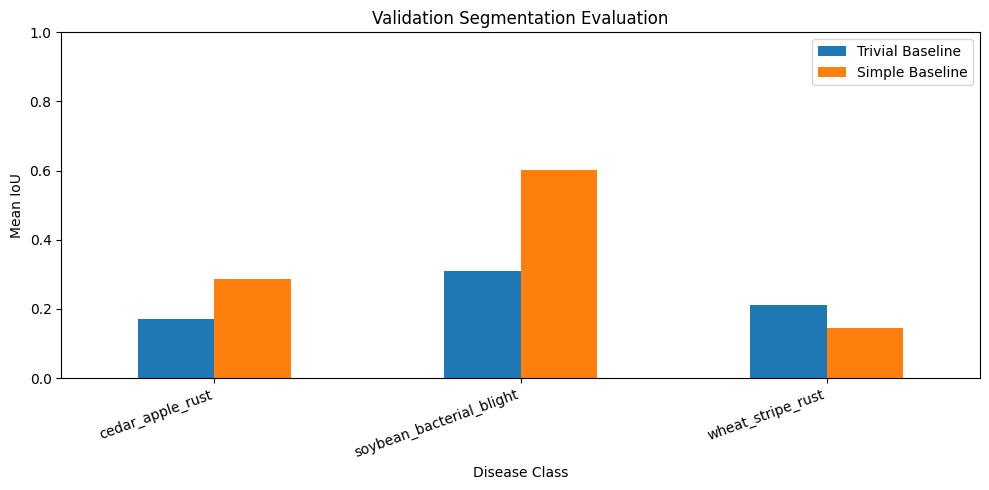


========== SEGMENTATION EVALUATION ==========
Dataset split: Validation
Evaluated images: 36
Metric: IoU
Trivial Baseline: 0.2301
Simple Baseline: 0.3442

Saved files:
/content/image-project-/results/segmentation_evaluation/final_review
/content/image-project-/results/segmentation_evaluation/validation_class_summary.csv
/content/image-project-/results/segmentation_evaluation/validation_iou_comparison.png
/content/image-project-/results/segmentation_evaluation/validation_overall_summary.csv
/content/image-project-/results/segmentation_evaluation/validation_per_image.csv

Evaluation completed successfully.


In [110]:

# ==========================================
# SEGMENTATION EVALUATION
# Trivial Baseline vs Simple Baseline
# Validation Set
# ==========================================

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from pathlib import Path

# ==========================================
# 1. FIND PROJECT AND SPLIT.CSV
# ==========================================

PROJECT_DIR = Path("/content/image-project-")

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        "Project folder not found. Please clone the GitHub repository first."
    )

split_files = list(PROJECT_DIR.rglob("split.csv"))

if not split_files:
    raise FileNotFoundError(
        "split.csv was not found inside the project folder."
    )

SPLIT_CSV = split_files[0]

print("Project directory:", PROJECT_DIR)
print("Split CSV:", SPLIT_CSV)

# ==========================================
# 2. DOWNLOAD / LOCATE DATASET
# ==========================================

DATASET_PATH = Path(
    kagglehub.dataset_download("alexzcheny/testdataset")
)

DATASET_ROOT = DATASET_PATH / "Dataset"

if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_ROOT}"
    )

print("Dataset directory:", DATASET_ROOT)

# ==========================================
# 3. LOAD DATASET MANIFEST
# ==========================================

df = pd.read_csv(SPLIT_CSV)

required_columns = [
    "class", "name", "image", "label", "split"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in split.csv: {missing_columns}"
    )

print("\nDataset shape:", df.shape)
print("\nSplit distribution:")
print(df["split"].value_counts())

# Evaluate validation samples only
val_df = df[
    df["split"].astype(str).str.strip().str.lower() == "val"
].copy()

if val_df.empty:
    raise ValueError("No validation samples found.")

print("\nValidation samples:", len(val_df))

# ==========================================
# 4. OUTPUT DIRECTORY
# ==========================================

OUTPUT_DIR = (
    PROJECT_DIR / "results" / "segmentation_evaluation"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 5. BASELINE METHODS
# ==========================================

def trivial_baseline(gray):
    """
    Global thresholding using a fixed threshold of 127.
    """
    return (gray > 127).astype(np.uint8)


def simple_baseline(gray):
    """
    Otsu thresholding followed by 3x3 Opening.
    """
    _, binary = cv2.threshold(
        gray,
        0,
        1,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    kernel = np.ones((3, 3), np.uint8)

    return cv2.morphologyEx(
        binary,
        cv2.MORPH_OPEN,
        kernel
    )

# ==========================================
# 6. IoU METRIC
# ==========================================

def calculate_iou(pred, truth):
    """
    Calculate Intersection over Union.

    IMPORTANT:
    This version treats every nonzero GT value
    as foreground. Confirm the meaning of 127
    and 255 before treating these scores as final.
    """

    pred = np.asarray(pred) > 0
    truth = np.asarray(truth) > 0

    if pred.shape != truth.shape:
        raise ValueError(
            "Prediction and ground-truth dimensions do not match."
        )

    intersection = np.logical_and(
        pred, truth
    ).sum()

    union = np.logical_or(
        pred, truth
    ).sum()

    return (
        float(intersection / union)
        if union > 0 else 1.0
    )

# ==========================================
# 7. EVALUATE VALIDATION IMAGES
# ==========================================

records = []
missing_files = []
failed_images = []

for _, row in val_df.iterrows():

    image_path = DATASET_ROOT / str(row["image"])
    mask_path = DATASET_ROOT / str(row["label"])

    # Check file existence
    if not image_path.is_file():
        missing_files.append(str(image_path))
        continue

    if not mask_path.is_file():
        missing_files.append(str(mask_path))
        continue

    # Read image and ground-truth mask
    image = cv2.imread(str(image_path))

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None or mask is None:
        failed_images.append(str(row["name"]))
        continue

    # Convert original image to grayscale
    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    # Check dimensions
    if gray.shape != mask.shape:
        raise ValueError(
            f"Dimension mismatch in {row['name']}: "
            f"image={gray.shape}, mask={mask.shape}"
        )

    # Generate segmentation predictions
    trivial_pred = trivial_baseline(gray)
    simple_pred = simple_baseline(gray)

    # Calculate IoU
    trivial_score = calculate_iou(
        trivial_pred, mask
    )

    simple_score = calculate_iou(
        simple_pred, mask
    )

    records.append({
        "name": row["name"],
        "class": row["class"],
        "split": row["split"],
        "trivial_iou": trivial_score,
        "simple_iou": simple_score
    })

# ==========================================
# 8. CHECK EVALUATION RESULTS
# ==========================================

results_df = pd.DataFrame(records)

print("\nSuccessfully evaluated:", len(results_df))
print("Missing files:", len(missing_files))
print("Failed image reads:", len(failed_images))

if missing_files:
    print("\nMissing file examples:")
    for file in missing_files[:10]:
        print(file)

if failed_images:
    print("\nFailed image examples:")
    print(failed_images[:10])

if results_df.empty:
    raise ValueError(
        "No validation images were successfully evaluated."
    )

# ==========================================
# 9. PER-IMAGE RESULTS
# ==========================================

print("\nPer-image results:")
display(results_df)

results_df.to_csv(
    OUTPUT_DIR / "validation_per_image.csv",
    index=False
)

# ==========================================
# 10. MEAN IoU PER CLASS
# ==========================================

class_summary = (
    results_df
    .groupby("class")[
        ["trivial_iou", "simple_iou"]
    ]
    .mean()
)

print("\nMean IoU per class:")
display(class_summary.round(4))

class_summary.to_csv(
    OUTPUT_DIR / "validation_class_summary.csv"
)

# ==========================================
# 11. OVERALL MEAN IoU
# ==========================================

overall_summary = results_df[
    ["trivial_iou", "simple_iou"]
].mean()

print("\nOverall Mean IoU:")
display(
    overall_summary.to_frame(
        name="Mean IoU"
    ).round(4)
)

overall_summary.to_csv(
    OUTPUT_DIR / "validation_overall_summary.csv"
)

# ==========================================
# 12. COMPARISON CHART
# ==========================================

ax = class_summary.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    ylabel="Mean IoU",
    title="Validation Segmentation Evaluation"
)

plt.xlabel("Disease Class")
plt.xticks(rotation=20, ha="right")
plt.legend(["Trivial Baseline", "Simple Baseline"])
plt.tight_layout()

chart_path = (
    OUTPUT_DIR / "validation_iou_comparison.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 13. FINAL REPORT
# ==========================================

print("\n========== SEGMENTATION EVALUATION ==========")

print("Dataset split: Validation")
print("Evaluated images:", len(results_df))
print("Metric: IoU")

print(
    "Trivial Baseline:",
    round(overall_summary["trivial_iou"], 4)
)

print(
    "Simple Baseline:",
    round(overall_summary["simple_iou"], 4)
)

print("\nSaved files:")

for file in sorted(OUTPUT_DIR.iterdir()):
    print(file)

print("\nEvaluation completed successfully.")



Class: cedar_apple_rust
Image: Apple_0226
Value 0: 300,447 pixels (73.35%)
Value 127: 108,217 pixels (26.42%)
Value 255: 936 pixels (0.23%)

Class: soybean_bacterial_blight
Image: Soybean_0154
Value 0: 299,033 pixels (73.01%)
Value 127: 82,755 pixels (20.20%)
Value 255: 27,812 pixels (6.79%)

Class: wheat_stripe_rust
Image: Wheat_C230514_0111
Value 0: 369,921 pixels (90.31%)
Value 127: 26,820 pixels (6.55%)
Value 255: 12,859 pixels (3.14%)


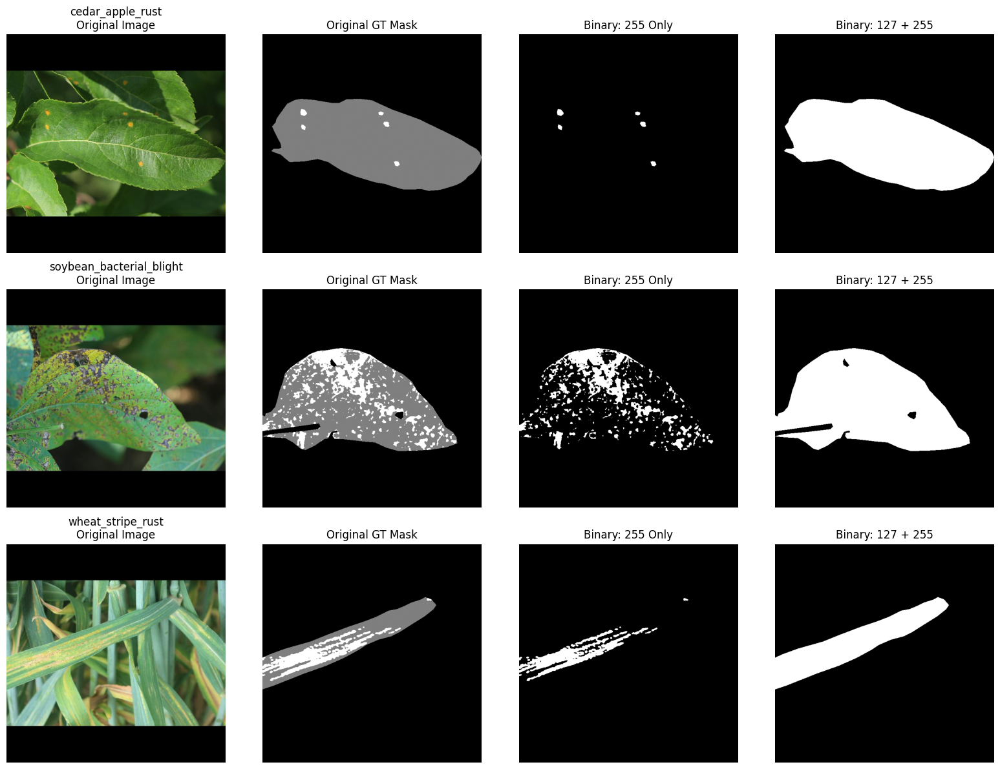

In [111]:


import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Check one validation sample from each class
classes = [
    "cedar_apple_rust",
    "soybean_bacterial_blight",
    "wheat_stripe_rust"
]

fig, axes = plt.subplots(len(classes), 4, figsize=(16, 12))

for row, class_name in enumerate(classes):

    # Select one validation sample
    sample = df[
        (df["class"] == class_name) &
        (df["split"] == "val")
    ].iloc[0]

    image_path = DATASET_ROOT / sample["image"]
    mask_path = DATASET_ROOT / sample["label"]

    image = cv2.imread(str(image_path))
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if image is None or mask is None:
        print(f"Could not read sample: {class_name}")
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Count original mask values
    values, counts = np.unique(mask, return_counts=True)
    total = mask.size

    print(f"\n{'='*50}")
    print(f"Class: {class_name}")
    print(f"Image: {sample['name']}")
    for value, count in zip(values, counts):
        print(
            f"Value {value}: {count:,} pixels "
            f"({count / total * 100:.2f}%)"
        )

    # Display original image
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{class_name}\nOriginal Image")

    # Display original mask values
    axes[row, 1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title("Original GT Mask")

    # Display only pixels equal to 255
    axes[row, 2].imshow(mask == 255, cmap="gray")
    axes[row, 2].set_title("Binary: 255 Only")

    # Display pixels equal to 127 or 255
    axes[row, 3].imshow(mask > 0, cmap="gray")
    axes[row, 3].set_title("Binary: 127 + 255")

    for col in range(4):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


FAILURE ANALYSIS & VISUAL REVIEW

Worst 5 samples:


,name,class,split,trivial_iou,simple_iou
8,Apple_0331,cedar_apple_rust,val,0.057584,0.064308
4,Wheat_C230514_0059,wheat_stripe_rust,val,0.074261,0.079119
7,Wheat_C230514_0050,wheat_stripe_rust,val,0.076566,0.082214
28,Wheat_C230514_0056,wheat_stripe_rust,val,0.101462,0.091688
26,Wheat_C230514_0048,wheat_stripe_rust,val,0.144905,0.107521



Best 3 samples:


,name,class,split,trivial_iou,simple_iou
18,Soybean_0055,soybean_bacterial_blight,val,0.326476,0.820740
33,Soybean_0045,soybean_bacterial_blight,val,0.193888,0.745871
22,Soybean_0088,soybean_bacterial_blight,val,0.227678,0.698588



Sample: Apple_0331
Class: cedar_apple_rust
Otsu threshold: 110.0
Trivial IoU (GT > 0): 0.0576
Simple IoU (GT > 0): 0.0643
Simple IoU (GT == 255): 0.0053


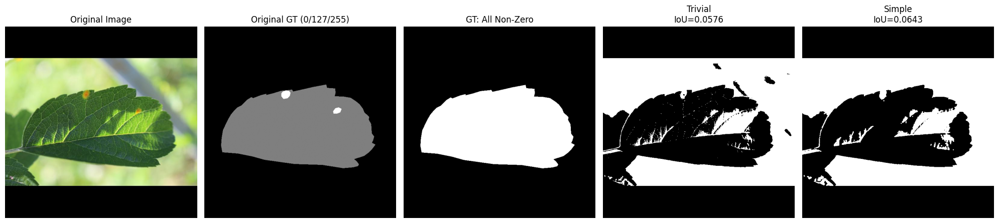


Sample: Wheat_C230514_0059
Class: wheat_stripe_rust
Otsu threshold: 86.0
Trivial IoU (GT > 0): 0.0743
Simple IoU (GT > 0): 0.0791
Simple IoU (GT == 255): 0.0228


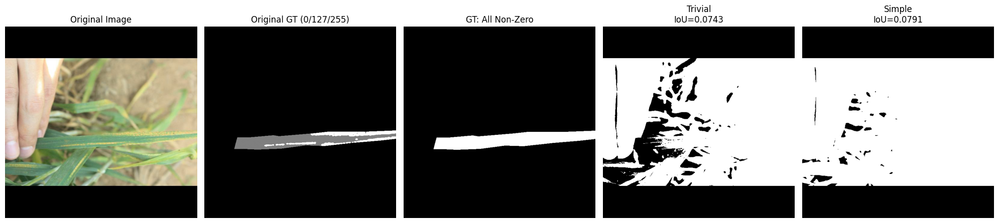


Sample: Wheat_C230514_0050
Class: wheat_stripe_rust
Otsu threshold: 76.0
Trivial IoU (GT > 0): 0.0766
Simple IoU (GT > 0): 0.0822
Simple IoU (GT == 255): 0.0069


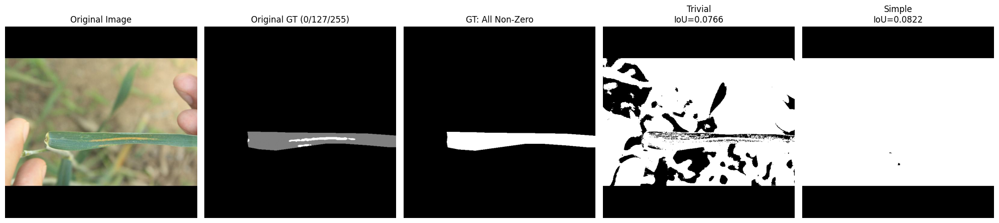


Sample: Wheat_C230514_0056
Class: wheat_stripe_rust
Otsu threshold: 69.0
Trivial IoU (GT > 0): 0.1015
Simple IoU (GT > 0): 0.0917
Simple IoU (GT == 255): 0.0269


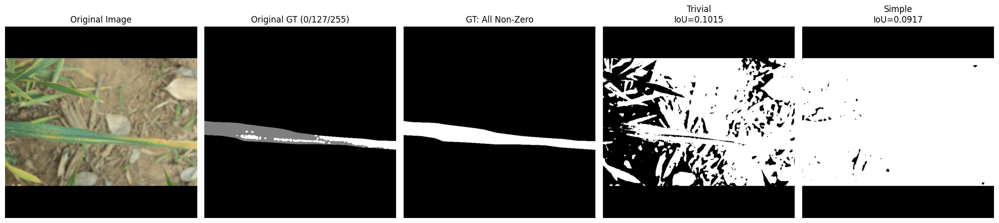


Sample: Wheat_C230514_0048
Class: wheat_stripe_rust
Otsu threshold: 72.0
Trivial IoU (GT > 0): 0.1449
Simple IoU (GT > 0): 0.1075
Simple IoU (GT == 255): 0.0161


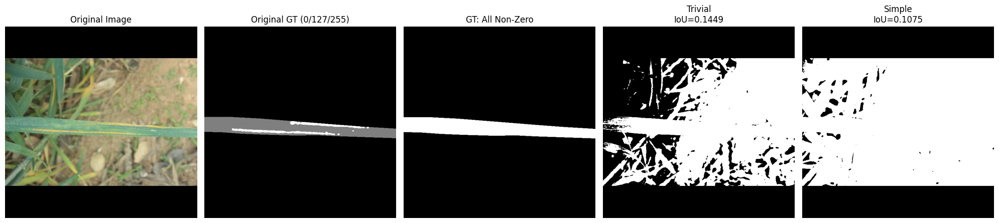


Sample: Soybean_0055
Class: soybean_bacterial_blight
Otsu threshold: 62.0
Trivial IoU (GT > 0): 0.3265
Simple IoU (GT > 0): 0.8207
Simple IoU (GT == 255): 0.2212


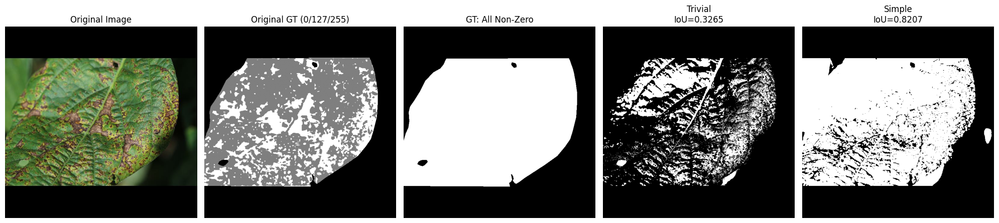


Sample: Soybean_0045
Class: soybean_bacterial_blight
Otsu threshold: 57.0
Trivial IoU (GT > 0): 0.1939
Simple IoU (GT > 0): 0.7459
Simple IoU (GT == 255): 0.2640


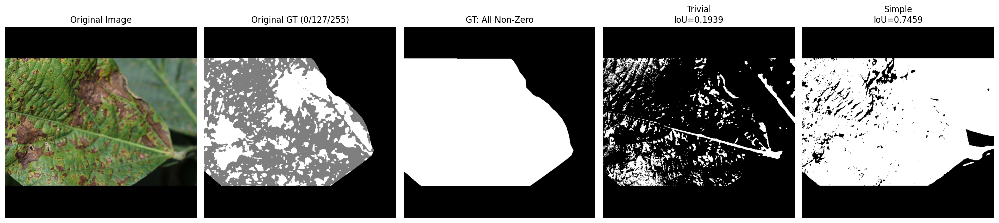


Sample: Soybean_0088
Class: soybean_bacterial_blight
Otsu threshold: 58.0
Trivial IoU (GT > 0): 0.2277
Simple IoU (GT > 0): 0.6986
Simple IoU (GT == 255): 0.1329


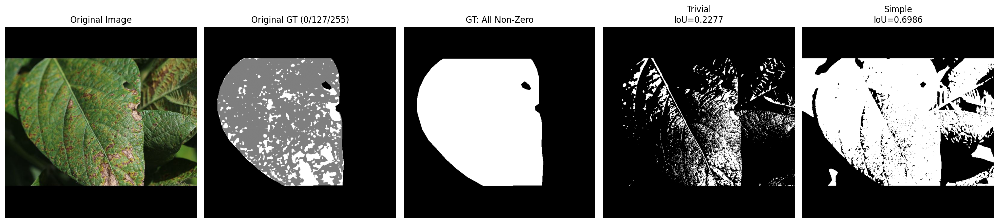


FINAL VALIDATION COMPARISON


,Baseline,Mean IoU,Median IoU
0,Trivial,0.2301,0.2238
1,Simple,0.3442,0.2476



Class-wise Mean IoU:


,trivial_iou,simple_iou
class,,
cedar_apple_rust,0.1699,0.2878
soybean_bacterial_blight,0.3085,0.6006
wheat_stripe_rust,0.2118,0.1443



Review files saved to:
/content/image-project-/results/segmentation_evaluation/final_review

FINAL REVIEW COMPLETED SUCCESSFULLY


In [112]:

# ============================================================
# FINAL FAILURE ANALYSIS & REVIEW
# Morphology and Evaluation Engineer
# ============================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Locate existing evaluation results
# ------------------------------------------------------------

eval_dir = Path("/content/image-project-/results/segmentation_evaluation")

per_image = pd.read_csv(eval_dir / "validation_per_image.csv")

# ------------------------------------------------------------
# 2. Select best and worst Simple Baseline samples
# ------------------------------------------------------------

worst_samples = per_image.sort_values(
    "simple_iou", ascending=True
).head(5)

best_samples = per_image.sort_values(
    "simple_iou", ascending=False
).head(3)

review_samples = pd.concat(
    [worst_samples, best_samples]
).drop_duplicates()

print("=" * 70)
print("FAILURE ANALYSIS & VISUAL REVIEW")
print("=" * 70)

print("\nWorst 5 samples:")
display(worst_samples)

print("\nBest 3 samples:")
display(best_samples)

# ------------------------------------------------------------
# 3. Find matching samples in the dataset manifest
# ------------------------------------------------------------

def find_manifest_sample(eval_row):

    # Try available identification columns
    possible_columns = ["name", "image"]

    for col in possible_columns:

        if col not in df.columns:
            continue

        value = str(eval_row[col]) if col in eval_row.index else None

        if value is None:
            continue

        matches = df[
            (df["split"] == "val") &
            (df[col].astype(str) == value)
        ]

        if len(matches) > 0:
            return matches.iloc[0]

    # Fallback: match using filename
    eval_name = str(eval_row.get("name", ""))

    if eval_name:
        matches = df[
            (df["split"] == "val") &
            (
                df["image"].astype(str).apply(
                    lambda x: Path(x).stem == Path(eval_name).stem
                )
            )
        ]

        if len(matches) > 0:
            return matches.iloc[0]

    return None

# ------------------------------------------------------------
# 4. Display original image, GT, trivial and simple predictions
# ------------------------------------------------------------

for _, eval_row in review_samples.iterrows():

    sample = find_manifest_sample(eval_row)

    if sample is None:
        print("Could not match sample:", eval_row.to_dict())
        continue

    image_path = DATASET_ROOT / sample["image"]
    mask_path = DATASET_ROOT / sample["label"]

    image_bgr = cv2.imread(str(image_path))
    gt_original = cv2.imread(
        str(mask_path), cv2.IMREAD_GRAYSCALE
    )

    if image_bgr is None or gt_original is None:
        print("Failed to read:", sample["name"])
        continue

    image_rgb = cv2.cvtColor(
        image_bgr, cv2.COLOR_BGR2RGB
    )

    gray = cv2.cvtColor(
        image_bgr, cv2.COLOR_BGR2GRAY
    )

    # Same Trivial baseline used in the previous evaluation
    trivial_prediction = gray > 127

    # Same Simple baseline: Otsu + 3x3 Opening
    otsu_threshold, otsu_mask = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    kernel = np.ones((3, 3), np.uint8)

    simple_prediction = cv2.morphologyEx(
        otsu_mask,
        cv2.MORPH_OPEN,
        kernel
    ) > 0

    # Existing evaluation convention:
    # all non-zero GT values are treated as foreground
    gt_binary = gt_original > 0

    # Alternative GT visualization for encoding review
    gt_255_only = gt_original == 255

    # IoU function
    def calculate_iou(prediction, truth):

        prediction = np.asarray(prediction, dtype=bool)
        truth = np.asarray(truth, dtype=bool)

        intersection = np.logical_and(
            prediction, truth
        ).sum()

        union = np.logical_or(
            prediction, truth
        ).sum()

        if union == 0:
            return 1.0

        return intersection / union

    trivial_iou = calculate_iou(
        trivial_prediction, gt_binary
    )

    simple_iou = calculate_iou(
        simple_prediction, gt_binary
    )

    iou_255_only = calculate_iou(
        simple_prediction, gt_255_only
    )

    # --------------------------------------------------------
    # 5. Print sample information
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("Sample:", sample["name"])
    print("Class:", sample["class"])
    print("Otsu threshold:", otsu_threshold)

    print(
        f"Trivial IoU (GT > 0): {trivial_iou:.4f}"
    )

    print(
        f"Simple IoU (GT > 0): {simple_iou:.4f}"
    )

    print(
        f"Simple IoU (GT == 255): {iou_255_only:.4f}"
    )

    # --------------------------------------------------------
    # 6. Visual comparison
    # --------------------------------------------------------

    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    axes[0].imshow(image_rgb)
    axes[0].set_title("Original Image")

    axes[1].imshow(gt_original, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title("Original GT (0/127/255)")

    axes[2].imshow(gt_binary, cmap="gray")
    axes[2].set_title("GT: All Non-Zero")

    axes[3].imshow(trivial_prediction, cmap="gray")
    axes[3].set_title(f"Trivial\nIoU={trivial_iou:.4f}")

    axes[4].imshow(simple_prediction, cmap="gray")
    axes[4].set_title(f"Simple\nIoU={simple_iou:.4f}")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 7. Final statistical comparison
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL VALIDATION COMPARISON")
print("=" * 70)

comparison = pd.DataFrame({
    "Baseline": ["Trivial", "Simple"],
    "Mean IoU": [
        per_image["trivial_iou"].mean(),
        per_image["simple_iou"].mean()
    ],
    "Median IoU": [
        per_image["trivial_iou"].median(),
        per_image["simple_iou"].median()
    ]
})

display(comparison.round(4))

# ------------------------------------------------------------
# 8. Class-wise comparison
# ------------------------------------------------------------

class_comparison = per_image.groupby("class")[
    ["trivial_iou", "simple_iou"]
].mean()

print("\nClass-wise Mean IoU:")
display(class_comparison.round(4))

# ------------------------------------------------------------
# 9. Save final review summary
# ------------------------------------------------------------

review_dir = eval_dir / "final_review"
review_dir.mkdir(parents=True, exist_ok=True)

worst_samples.to_csv(
    review_dir / "worst_5_samples.csv",
    index=False
)

best_samples.to_csv(
    review_dir / "best_3_samples.csv",
    index=False
)

comparison.to_csv(
    review_dir / "final_baseline_comparison.csv",
    index=False
)

class_comparison.to_csv(
    review_dir / "class_wise_comparison.csv"
)

print("\nReview files saved to:")
print(review_dir)

print("\nFINAL REVIEW COMPLETED SUCCESSFULLY")
